P1.
1.Each row represents the measurements taken from a Fine Needle Aspirate (FNA) of a breast mass for a single patient. The response variable is the diagnosis of the tumor, which has two classes: Malignant (cancerous, typically encoded as 0 in sklearn) and Benign (non-cancerous, encoded as 1).


2.The dataset contains 30 numeric predictors capturing the cell nuclei's characteristics (mean, standard error, and "worst" values for features like radius, texture, perimeter, area, smoothness, concavity, etc.). I will use all 30 morphological features as they provide strong signals for distinguishing between malignant and benign cells.


3.There are 357 Benign and 212 Malignant samples. Although Benign is more frequent, the ratio is around 1.7:1. This is reasonably balanced, meaning we do not need extreme resampling techniques, but we must still be careful not to let accuracy alone fool us.


4.In the context of my dataset:
False Positive (FP): Predicting Malignant when the tumor is actually Benign. (Causes unnecessary patient anxiety, extra tests, and potentially unnecessary surgery).
False Negative (FN): Predicting Benign when the tumor is actually Malignant. (Causes a missed cancer diagnosis, delays treatment, and can be life-threatening).


5.I am significantly more concerned about False Negatives (FN). Because in medical diagnostics, the cost of missing a malignant tumor is fatal. While a False Positive leads to temporary stress and follow-up tests, a False Negative can cost a patient's life. Therefore, our modeling strategy should prioritize Recall (catching as many true malignancies as possible), even if it means accepting a slightly higher False Positive rate.


In [13]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score


P2.1
The dataset contains mostly continuous numerical features and one categorical feature.

In [14]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# In sklearn, 1 = Benign, 0 = Malignant.
# To make "Malignant" the Positive class (what we want to detect), we invert y.
y = 1 - y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1, stratify=y)


2.The dataset contains no missing values.

3.Yes,the response variable (y) in the raw dataset is categorical.It consists of strings 'B' (Benign) and 'M' (Malignant). Because classifiers require numerical labels, I encoded the response variable into binary format: Malignant = 1 (Positive class) and Benign = 0 (Negative class). This ensures the model correctly identifies the malignant tumors as the positive class we want to detect.



4.I used a 75/25 train-test split (stratify=y to maintain the class ratio) and will use 5-fold Cross-Validation (StratifiedKFold) on the training data to evaluate the models and tune the KNN hyperparameter.
(I used a 75/25 train-test split because it provides a good balance for this dataset size (569 samples). A 25% test set (approx. 142 samples) is large enough to provide statistically reliable evaluation metrics (like Recall and AUC), while the remaining 75% gives the models sufficient data to learn complex patterns.
stratify=y Because the dataset is slightly imbalanced (Benign > Malignant). stratify=y ensures that both the 75% training set and the 25% test set have the exact same percentage of malignant cases as the original dataset. Without it, we might accidentally get a test set with very few cancers, leading to unreliable results.)

5.Yes, some predictors should be standardized. Because our features have vastly different scales (e.g., area can be as big as 2250 vs. smoothness can be as small as 0.0832). Without it, KNN distances would be dominated by large numbers, and Logistic Regression's regularization would be unfair. I will apply StandardScaler inside a make_pipeline.

P3.
Fit final KNN with the best K :
According to the CV graph below, K=1 and K=3 achieved the highest mean accuracy (~0.969). However, K=1 is likely to be overfitting. Therefore, I selected K=3 (or K=11, which is more stable) as the optimal hyperparameter.

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


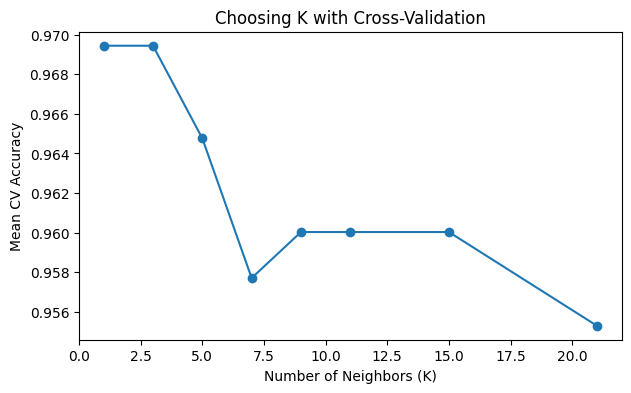

In [15]:
# 1. Logistic Regression
# Train the model on the training data；log=logistic
log_reg.fit(X_train, y_train)
# Get the predicted probabilities for the Positive class (Malignant = 1)
prob_log = log_reg.predict_proba(X_test)[:, 1]

# 2. LDA
# Initialize the LDA classifier
lda = LinearDiscriminantAnalysis()
# Train the LDA model
lda.fit(X_train, y_train)
# Get the predicted probabilities for the Positive class (Malignant = 1)
prob_lda = lda.predict_proba(X_test)[:, 1]

# 3. QDA
# Initialize the QDA classifier
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)
prob_qda = qda.predict_proba(X_test)[:, 1]

# 4. KNN (Selecting K via Cross-Validation)
# Define a list of odd numbers for K to avoid ties in voting
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
# Create an empty list to store the mean CV scores
cv_scores = []
# Set up 5-fold Cross-Validation.
# shuffle=True randomizes the data, random_state ensures reproducibility.
# StratifiedKFold maintains the class ratio in each fold.
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# Loop through each K value to evaluate performance
for k in k_values:
  # Create a pipeline: Scale the data, then apply KNN with current K
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    # Perform 5-fold CV on the training data and get the accuracy scores for each fold
    scores = cross_val_score(knn, X_train, y_train, cv=kfold)
    # Calculate the average accuracy across the 5 folds and append to the list
    cv_scores.append(scores.mean())

# Plot K vs CV Accuracy
# Set the size of the figure (width=7, height=4)
plt.figure(figsize=(7, 4))
# Create a line plot: X-axis is k_values, Y-axis is cv_scores.
# marker="o" adds a circle dot at each data point for better visibility.
plt.plot(k_values, cv_scores, marker="o")
# Add labels to the X and Y axes
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy")
# Add a title to the graph
plt.title("Choosing K with Cross-Validation")
# Display the plot
plt.show()

# Fit final KNN with the best K
# Based on the CV graph, K=3 is chosen (high accuracy but more stable than K=1)
best_k = 3
# Build the final pipeline using the optimal K
knn_final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
# Train the final model on the full training set
knn_final.fit(X_train, y_train)
# Get the predicted probabilities for the Positive class (Malignant = 1)
prob_knn = knn_final.predict_proba(X_test)[:, 1]


P4.
1. Threshold Choice:
As discussed in Part 1, False Negatives (missing a malignant tumor) are fatal. Therefore, I did not use the default 0.50 threshold. I set the threshold to 0.30. This is a decision rule—not a change to the model's fitted curve. Lowering the threshold increases our sensitivity to malignancies (Recall), at the cost of more False Positives.

2. Model Comparison Metrics


**Table 1: Model Comparison Metrics (Threshold = 0.30)**

| Model | Accuracy | Precision | Recall | Specificity | F1 | ROC-AUC |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Logistic Regression** | 0.972 | 0.962 | 0.962 | 0.978 | 0.962 | 0.997 |
| **LDA** | 0.923 | 0.938 | 0.849 | 0.967 | 0.891 | 0.992 |
| **QDA** | 0.951 | 0.942 | 0.925 | 0.967 | 0.933 | 0.990 |
| **KNN** | 0.958 | 0.943 | 0.943 | 0.967 | 0.943 | 0.992 |

In [16]:
# Define a function to calculate all metrics at a given threshold
def evaluate_model(y_true, probs, threshold):
  # Convert probabilities to binary predictions based on the threshold
    preds = (probs >= threshold).astype(int)
     # Get the 4 values of the confusion matrix: True Neg, False Pos, False Neg, True Pos
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()

     # Calculate classification metrics
    accuracy = accuracy_score(y_true, preds)
    precision = precision_score(y_true, preds)
    recall = recall_score(y_true, preds)

    # Specificity is not built-in in sklearn, calculate manually: TN / (TN + FP)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_true, preds)

     # AUC uses probabilities, not class predictions (threshold-independent)
    auc = roc_auc_score(y_true, probs)

    return [accuracy, precision, recall, specificity, f1, auc], [tn, fp, fn, tp]

# Using a strict threshold of 0.30 to minimize False Negatives
threshold = 0.30

# Store model names and their predicted probabilities in a dictionary
models = {"Logistic Regression": prob_log, "LDA": prob_lda, "QDA": prob_qda, "KNN": prob_knn}
results = []

print(f"--- Evaluation at Threshold = {threshold} ---")

# Loop through each model to evaluate its performance
for name, probs in models.items():
  # Call the function
    metrics, cm = evaluate_model(y_test, probs, threshold)

    # add the model name and its metrics to the results list
    results.append([name] + metrics)

     # Print the confusion matrix details for each model
    print(f"\n{name} Confusion Matrix:")
    print(f"TN: {cm[0]}, FP: {cm[1]}, FN: {cm[2]}, TP: {cm[3]}")

# Create Comparison Table
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"])
print("\n--- Final Comparison Table ---")
display(results_df.round(3))



--- Evaluation at Threshold = 0.3 ---

Logistic Regression Confusion Matrix:
TN: 88, FP: 2, FN: 2, TP: 51

LDA Confusion Matrix:
TN: 87, FP: 3, FN: 8, TP: 45

QDA Confusion Matrix:
TN: 87, FP: 3, FN: 4, TP: 49

KNN Confusion Matrix:
TN: 84, FP: 6, FN: 3, TP: 50

--- Final Comparison Table ---


,Model,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
0,Logistic Regression,0.972,0.962,0.962,0.978,0.962,0.997
1,LDA,0.923,0.938,0.849,0.967,0.891,0.992
2,QDA,0.951,0.942,0.925,0.967,0.933,0.990
3,KNN,0.937,0.893,0.943,0.933,0.917,0.968


P5.Refelction
In this medical application, Accuracy alone is misleading because False Negatives (FN) are fatal. Therefore, Recall (Sensitivity) is the most informative metric. At our 0.30 threshold, Logistic Regression achieves the highest Recall (0.962) and the highest ROC-AUC (0.997), successfully catching 96.2% of actual malignant cases. Interestingly, QDA (0.925) and KNN (0.943) perform much better than LDA (0.849) in terms of Recall. LDA misses about 15% of cancers at this threshold. Logistic Regression provides the best balance of high Recall and high Specificity, making it the most reliable model for patient safety.

P6.
The ROC curve confirms the previous findings. Logistic Regression has the highest AUC (0.997), meaning it has the strongest discriminative ability. As the curve shows, the blue line hugs the top-left corner almost perfectly. An AUC of ~0.99 for all models tells us that they are all excellent at ranking patients by risk, independent of the threshold. However, when we actually need to make a decision (like at 0.30), Logistic Regression's high curve translates to fewer missed cancers (FN).‌



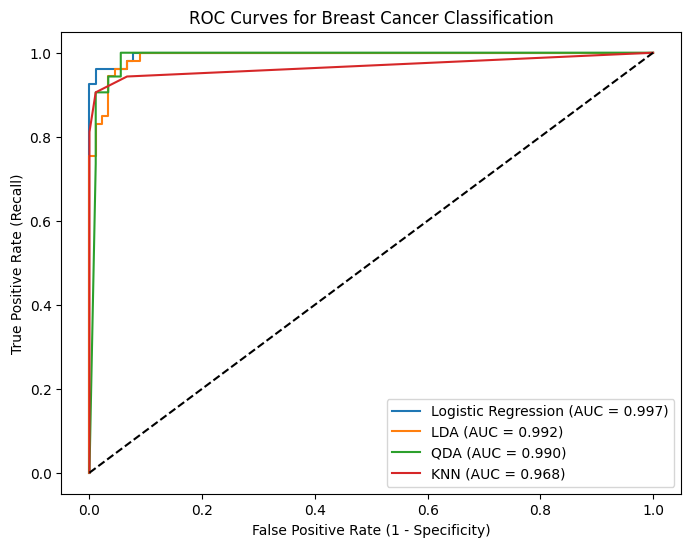

In [17]:
# Set the size of the plot (width=8, height=6)
plt.figure(figsize=(8, 6))

# Loop through each model in the dictionary
for name, probs in models.items():
  # Calculate the False Positive Rate (fpr), True Positive Rate (tpr), and thresholds
    # (We use '_' for thresholds because we don't need them for the plot)

# Plot the ROC curve for the current model
    # The label uses f-string to dynamically show the model name and its calculated AUC score
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs):.3f})")

# Plot a diagonal dashed line representing a random guess (AUC = 0.5)
plt.plot([0, 1], [0, 1], linestyle="--", color="black")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves for Breast Cancer Classification")
plt.legend()
plt.show()

P7.Final Analysis
1. Compare the performance of your four classifiers. What are the most important differences?
At our chosen 0.30 threshold, all four models had excellent overall accuracy (over 92%) and very high ROC-AUC scores (over 0.99), meaning they are generally very good at distinguishing between malignant and benign tumors. However, the most important difference appeared in Recall (the ability to catch actual cancers). Logistic Regression performed the best with a Recall of 0.962. QDA and KNN also performed well (Recall of 0.925 and 0.943). The biggest surprise was LDA, which had a significantly lower Recall (0.849), meaning it missed about 15% of malignant cases. Therefore, despite LDA's high accuracy, its high missed-cancer rate makes it the riskiest choice.

2. Identify the model you would deploy for this specific application and justify the choice using your results and the consequences of classification errors.
I would select Logistic Regression as the best model for this project. At a threshold of 0.30, it achieved the highest recall (0.962) and the highest ROC-AUC (0.997). It detected 51 malignant cases, missed 2 malignant cases, and produced 2 false alarms among benign cases. Because missing a malignant tumor can have serious consequences, its high recall is especially important. However, I would not deploy this model for real-world diagnosis based on this dataset alone. It would need further testing with larger, independent datasets and clinical validation.

3. Explain one limitation of your analysis.
A major limitation is the dataset size and missing information. The dataset only contains 569 samples, which might not capture the full diversity of real-world patients. Furthermore, it only includes numerical measurements from cell nuclei. It lacks crucial clinical information, such as the patient's age, genetic history (like BRCA mutations), and actual mammogram images. A model trained purely on these isolated numbers might not generalize well to different hospitals or diverse populations.

4. What additional information or data would you want before using this model in the real world?
Before deploying this in a real hospital, I would want to add patient demographics and clinical history (e.g., age, family history of cancer) to the model. I would also want to train it on a much larger dataset collected from multiple different hospitals to ensure it is robust and not overfitted to one specific location's data. Finally, integrating actual medical imaging (like ultrasound or mammogram scans) alongside these numerical features would provide a much more comprehensive diagnosis.